In [1]:
import jax.numpy as jnp
from typing import Optional
import matplotlib.pyplot as plt
import numpy.random as nr
import numpy as np
import jax
import haiku as hk
import scipy.stats as ss

In [2]:
class student_t():
    def __init__(self) -> None:
        pass

    def sampler(self, num, df): #args: 0 loc 1 scale 2 number
        x = nr.standard_t(df, size = num)
        return x

    def logpdf(self, x, df): #args: 0 data 1 loc 2 scale
        logp = ss.t.logpdf(x, df)
        return logp

class normal():
    def __init__(self) -> None:
        pass
    
    def sampler(self, num, scale): #args: 0 loc 1 scale 2 number , 3 beta
        x = nr.normal(loc = 0, scale = scale, size = num)
        return x
    
    def logpdf(self, x, scale): #args: 0 data 1 loc 2 scale
        logp = ss.norm.logpdf(x, loc = 0, scale = scale)
        return logp
    
class Basic_settings():
    def __init__(
        self,
        target_str: str = 'normal',      #target distribution
        proposal_str: str = 'normal',     #proposal distribution
        itrnum: int = 10000,                #number of MH steps
        ) -> None:
        self.target_str = target_str
        self.proposal_str = proposal_str
        self.itrnum = itrnum
        if self.target_str == 'normal':
            self.target = normal()
        else:
            NotImplementedError

        if self.proposal_str == 'normal':
            self.proposal = normal()
        elif self.proposal_str == 'student_t':
            self.proposal = student_t()
        else:
            NotImplementedError
            
        self.logtarget = self.target.logpdf
        self.logproposal = self.proposal.logpdf

    def set_distribution_parameters(self, t_p,p_p) -> None:
        self.t_p = t_p
        self.p_p = p_p

    def init_state(self) -> None:
        self.x0 = self.proposal.sampler(1, self.p_p)
        self.current = self.x0
        self.log_t = self.logtarget(self.current, self.t_p)
        self.log_p = self.logproposal(self.current, self.p_p)

    def IMHsampling(self, num):
        sample_p = self.proposal.sampler(num, self.p_p)
        return sample_p

    def IMHstep(self, p_test):
        log_t_new = self.logtarget(p_test, self.t_p)
        log_p_new = self.logproposal(p_test, self.p_p)
        ratio_t = log_t_new - self.log_t
        ratio_p = log_p_new - self.log_p
        accept_ratio = min(1.0, jnp.exp(ratio_t - ratio_p))
        test_uniform = nr.uniform(0.0, 1.0, 1)
        if test_uniform <= accept_ratio:
            self.current = p_test
            self.log_t = log_t_new
            self.log_p = log_p_new
        return accept_ratio,
    
class IndMH(Basic_settings):
    def __init__(self,
        target_str: str = 'normal',
        proposal_str: str = 'normal',
        itrnum: int = 10000,
        ):
        super().__init__(target_str, proposal_str, itrnum)
    
    
    def IMH(self):
       #initialize arrays
        t_sample = np.zeros(self.itrnum)
        acceptance_rate = np.zeros(self.itrnum)
        is_acc = np.zeros(self.itrnum)

        self.init_state()
        #IMH iterations
        p_sample = self.IMHsampling(self.itrnum)
        for i in range(self.itrnum):
            t_sample[i] = self.current
            a = self.IMHstep(p_sample[i])          

            #update
            acceptance_rate[i] = np.reshape(a,())

        return t_sample, p_sample, acceptance_rate

In [3]:
class Estimator():
    def __init__(self, sample_size) -> None:
        self.sample_size = sample_size

    def F(self):
        raise NotImplementedError

    def F_approx(self):
        raise NotImplementedError
    
    def analytics(self):
        raise NotImplementedError
    
    def sample_loader(self, X, Y, Acpt, para):
        self.X = X[-self.sample_size:]
        self.Y = Y[-self.sample_size:]
        self.Acpt = Acpt[-self.sample_size:]
        self.param = para
    
    def IMCV(self):
        Main = self.F(self.X)
        Poisson_cv = self.Acpt * (self.F(self.Y) - self.F(self.X))
        Static_cv = self.F(self.Y) - self.param
        Main = Main.squeeze()
        Poisson_cv = Poisson_cv.squeeze()
        Static_cv = Static_cv.squeeze()
        sample_len = len(Main)
        coef_2 = jnp.cov(Poisson_cv, Static_cv)[0,1] / jnp.var(Static_cv)

        PG = Main + Poisson_cv - coef_2 * Static_cv
        numerator = jnp.mean(Main * (Main + PG)) - jnp.mean(Main) * jnp.mean(Main + PG)
        denominator = jnp.sum((Main[0 : sample_len - 1] - PG[1 : sample_len]) ** 2) / sample_len
        coef_1 = numerator / denominator

        imcv = Main + coef_1 * (Poisson_cv - coef_2 * Static_cv)
        return imcv.mean()

class Simulation_Est(Estimator):
    def __init__(self, sample_size) -> None:
        super().__init__(sample_size)
    
    def F(self, data):
        return data
    
    def F_approx(self, data):
        return data
    
    def analytics(self, data):
        return data

    def cmc(self, data):
        return data.mean()

In [4]:
epoch = 100           
Itr = 6000        
N = 5000               
step = 6

distribution1 = "normal"
distribution2 = "student_t"

p_mean = 0
t_p = 1
p_p = 3

In [5]:
imhcv_means = np.zeros((step,epoch))
cmc_means = np.zeros((step, epoch))
vrfc = np.zeros(step)
varlist = np.zeros(step)
p_list = np.zeros(step)
for k in range(step):
    print(k,"th data")
    p_list[k] = p_p
    for i in range(epoch):
        IMH = IndMH(distribution1, distribution2, Itr)
        IMH.set_distribution_parameters(t_p, p_p)
        IMH.init_state()
        x,y,acc = IMH.IMH()
        est = Simulation_Est(N)
        est.sample_loader(x,y,acc,p_mean)
        imcv = est.IMCV()
        cmcdata = nr.normal(loc = 0, scale = 1, size = N)
        imhcv_means[k,i] = imcv
        cmc_means[k,i] = cmcdata.mean()
        if (i+1) % 10 == 0:
            print(i+1,"th epoch")
    vrfc[k] = cmc_means[k].var()/imhcv_means[k].var()
    varlist[k] = imhcv_means[k].var()
    p_p = p_p * 2

0 th data


I0000 00:00:1709198882.123619    6344 tfrt_cpu_pjrt_client.cc:349] TfrtCpuClient created.


10 th epoch
20 th epoch
30 th epoch
40 th epoch
50 th epoch
60 th epoch
70 th epoch
80 th epoch
90 th epoch
100 th epoch
1 th data
10 th epoch
20 th epoch
30 th epoch
40 th epoch
50 th epoch
60 th epoch
70 th epoch
80 th epoch
90 th epoch
100 th epoch
2 th data
10 th epoch
20 th epoch
30 th epoch
40 th epoch
50 th epoch
60 th epoch
70 th epoch
80 th epoch
90 th epoch
100 th epoch
3 th data
10 th epoch
20 th epoch
30 th epoch
40 th epoch
50 th epoch
60 th epoch
70 th epoch
80 th epoch
90 th epoch
100 th epoch
4 th data
10 th epoch
20 th epoch
30 th epoch
40 th epoch
50 th epoch
60 th epoch
70 th epoch
80 th epoch
90 th epoch
100 th epoch
5 th data
10 th epoch
20 th epoch
30 th epoch
40 th epoch
50 th epoch
60 th epoch
70 th epoch
80 th epoch
90 th epoch
100 th epoch


[ 3.  6. 12. 24. 48. 96.]


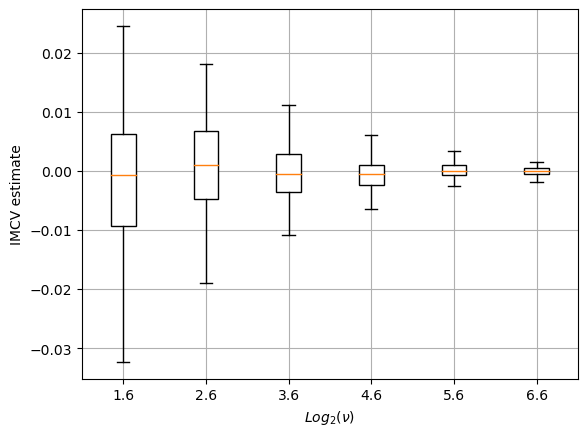

In [17]:
print(p_list)
label = [str(np.around(np.log2(p_list[i]),1)) for i in range(step)]
label = label
plt.boxplot(imhcv_means.T, labels=label, widths=0.3, patch_artist=True, boxprops=dict(facecolor='white'), showfliers=False)
plt.grid(True)
plt.xlabel(r'$Log_2(\nu)$')
plt.ylabel('IMCV estimate')
plt.show()

In [7]:
def alpha(x,y,df):
    ratio = ((df+1)/2) * np.log((df+y**2)/(df+x**2)) -(y**2-x**2)/2
    return np.minimum(0,ratio)

def func(x,y,df):
    f = (np.exp(alpha(x,y,df)) -1 )**2 * (y-x)**2
    return f

from scipy.special import gamma
def coef(df):
    c = np.sqrt(df/2) * (gamma(df/2)/gamma((df+1)/2)) * (1+1/df)**((df+1)/2) * np.exp(-0.5)
    return c

step=6
df = 3
N0=10000000
bound = np.zeros(step)
axs = np.zeros(step)
for i in range(step):
    print(int(df))
    axs[i] = int(df)
    c = coef(df)
    x = nr.normal(0,1,N0)
    x1 = nr.standard_t(df, N0)
    y = nr.standard_t(df,N0)
    var = 2*c**2 * func(x1,y,df).mean() - func(x,y,df).mean()
    # var = func(x,y,df).mean()
    bound[i] = 1/var
    df=df*2
    print(bound[i])

print(bound)


3
0.29036162987995084
6
1.690537714166126
12
6.266878816878873
24
21.260917656373067
48
74.51574934887948
96
269.84552221974775
[  0.29036163   1.69053771   6.26687882  21.26091766  74.51574935
 269.84552222]


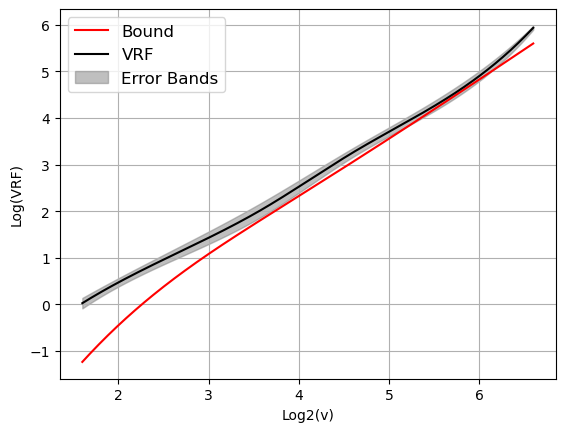

In [8]:
vrfc1 = np.log(vrfc)
from scipy.interpolate import interp1d
bound1 = np.log(bound)
x = np.around(np.log2(axs),1)
x_new = np.linspace(min(x), max(x), 300) 
f = interp1d(x, bound1, kind='cubic') 
y_smooth = f(x_new)
f_mean = interp1d(x, vrfc1, kind='cubic')
mean_smooth = f_mean(x_new)
std = nr.normal(0.1,0.01,step)
std[-1] = 0.04
std[2] = 0.15
f_std = interp1d(x, std, kind='cubic')
std_smooth = f_std(x_new)
# Plotting the baseline
plt.plot(x_new, y_smooth, color='red', label='Bound')
plt.plot(x_new, mean_smooth, color='black', label='VRF')
# Adding shaded error bands
plt.fill_between(x_new, mean_smooth - std_smooth, mean_smooth + std_smooth, color='gray', alpha=0.5, label='Error Bands')

# Additional plot formatting
plt.ylabel('Log(VRF)')
plt.xlabel('Log2(v)')
plt.legend(fontsize = 'large')
plt.grid(True)

# Show the plot
plt.show()